In [1]:
import time 

start_time = time.perf_counter()

#Environment Variables
run_name = "cell_sampler_2" # change per experiment, e.g. "model_unbalanced"

In [2]:
#This script loads and verifies the test dataset for the GeoGuessr project
import pandas as pd
from pathlib import Path

image_dir = Path("/work/cssema416/202710/11/datasets/OpenWorld/extracted_train")
out_dir = Path("output")/run_name
out_dir.mkdir(parents=True, exist_ok=True)

#Verifies the shape
csv_path = "/work/cssema416/202710/11/datasets/OpenWorld/train.csv"
cols = ["id", "latitude", "longitude", "cell", "sequence", "country", "unique_country"]
df_all = pd.read_csv(csv_path, usecols=cols)
df = df_all                                              # so the existing prints below still work

print("Dataset shape:", df.shape)
print(df.head())
print(df.columns.tolist())

#This confirms data loaded as expected
print("Metadata rows:", len(df))
print("Metadata columns:", len(df.columns))

#nunique is num of unique elements
print("Unique countries:", df["country"].nunique())

print("Country counts:")
print(df["country"].value_counts().head())

Dataset shape: (4894684, 7)
                 id   latitude   longitude country                sequence  \
0  3859149887465501 -43.804769 -176.614093      NZ  1qOCfogkQ5uE4ZvEf_4n2A   
1   574181207305439 -43.796611 -176.660483      NZ  5rdtj6tui6qdlg8q812ul2   
2   333574322129026 -43.818092 -176.578383      NZ  nJcst1M2bFUxSOA54CZiy9   
3   636305258168031 -44.052910 -176.633065      NZ  BGSwcf0pLCE5bMUWdKTeqk   
4   166741299029322 -43.748077 -176.329626      NZ  05pt8HKnLCf47UTGPrxuzB   

     cell unique_country  
0  (0, 8)             NZ  
1  (0, 8)             NZ  
2  (0, 8)             NZ  
3  (0, 8)             NZ  
4  (0, 8)             NZ  
['id', 'latitude', 'longitude', 'country', 'sequence', 'cell', 'unique_country']
Metadata rows: 4894684
Metadata columns: 7
Unique countries: 222
Country counts:


country
US    1218664
DE     272282
FR     242074
RU     222351
JP     209205
Name: count, dtype: int64


In [3]:
import os, random
from concurrent.futures import ThreadPoolExecutor

K = None # number of extracted folders to use; None = all

def list_folder(folder):
    return {e.name[:-4]: e.path for e in os.scandir(folder) if e.name.lower().endswith(".jpg")}

df = df_all.copy() # fresh copy each run
df["id"] = df["id"].astype(str).str.strip()

subdirs = sorted(e.path for e in os.scandir(image_dir) if e.is_dir())
if K is not None:
    subdirs = random.Random(0).sample(subdirs, K)

image_lookup = {}
with ThreadPoolExecutor(max_workers=min(16, len(subdirs))) as ex:
    for d in ex.map(list_folder, subdirs):
        image_lookup.update(d)

df["image_path"] = df["id"].map(image_lookup)
print("files found:", len(image_lookup), "| rows matched:", df["image_path"].notna().sum())

df = df.dropna(subset=["image_path"]).reset_index(drop=True)
print("country share in subset:\n", df["country"].value_counts(normalize=True).head())

files found: 4894684 | rows matched: 4894684


country share in subset:
 country
US    0.248977
DE    0.055628
FR    0.049457
RU    0.045427
JP    0.042741
Name: proportion, dtype: float64


In [4]:
print(df["country"].value_counts().to_string())

country
US    1218664
DE     272282
FR     242074
RU     222351
JP     209205
AU     162138
BR     140599
GB     137648
SE     131816
IT     115084
PL     106124
ES      96508
CA      84299
TH      74763
PK      64025
RO      56812
MX      53468
ZA      53443
PT      51551
IN      50604
NL      49666
DK      46230
FI      45974
NZ      45530
TR      43877
GR      42007
AR      41581
HU      41472
AT      39249
ID      36582
IE      36518
TW      31941
NO      27940
CO      26155
EE      25916
BY      25144
BE      24663
LV      24497
CL      22869
HR      22034
MA      20685
CZ      20407
RS      20366
CH      19917
SK      19474
BO      17577
MD      15250
AE      14954
PE      14672
CY      14593
TN      13686
BG      13440
LT      12867
VN      12170
EC      11987
PY      11891
KW      10845
OM      10537
ZM       9987
NG       9970
PH       9872
MY       9225
SI       9202
GH       8856
BH       8567
BD       8482
NI       8101
UG       8092
IR       7842
CN       7757
SL       773

In [5]:
baseline_country = "US" #this was the highest occuring country in dataset

data = df["country"]
y_pred = [baseline_country] * len(data)

accuracy = (data == y_pred).mean()

print("Baseline country:", baseline_country)
print("Baseline accuracy:", accuracy)
print("Number of images:", len(data))
print("Number of correct guesses:", len(data) * accuracy)
print("Number of countries:", data.nunique())

Baseline country: US
Baseline accuracy: 0.2489770534727063
Number of images: 4894684
Number of correct guesses: 1218664.0
Number of countries: 222


In [6]:
import torch
import torchvision.models as models
import torch.nn as nn
import torchvision.transforms as transforms
from PIL import Image
from transformers import CLIPModel

transform = transforms.Compose([
    # Squash the whole image to 224x224 instead of center-cropping: the crop cut off
    # the left/right edges, which hold most driving-side cues (shoulders, oncoming traffic, signs)
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.48145466, 0.4578275, 0.40821073],
                         std=[0.26862954, 0.26130258, 0.27577711]),
])

clip = CLIPModel.from_pretrained("openai/clip-vit-base-patch32")

class CLIPFeatures(nn.Module):
    def __init__(self, clip):
        super().__init__()
        self.vision = clip.vision_model
        self.proj = clip.visual_projection
    def forward(self, x):
        return self.proj(self.vision(pixel_values=x).pooler_output)

model = CLIPFeatures(clip)
feat_dim = clip.config.projection_dim

print(model)

/home/tokoyol/miniconda3/envs/CSSE416/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 398/398 [00:00<00:00, 16139.58it/s]

CLIPFeatures(
  (vision): CLIPVisionModel(
    (embeddings): CLIPVisionEmbeddings(
      (patch_embedding): Conv2d(3, 768, kernel_size=(32, 32), stride=(32, 32), bias=False)
      (position_embedding): Embedding(50, 768)
    )
    (pre_layrnorm): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
    (encoder): CLIPEncoder(
      (layers): ModuleList(
        (0-11): 12 x CLIPEncoderLayer(
          (self_attn): CLIPAttention(
            (k_proj): Linear(in_features=768, out_features=768, bias=True)
            (v_proj): Linear(in_features=768, out_features=768, bias=True)
            (q_proj): Linear(in_features=768, out_features=768, bias=True)
            (out_proj): Linear(in_features=768, out_features=768, bias=True)
          )
          (layer_norm1): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
          (mlp): CLIPMLP(
            (activation_fn): QuickGELUActivation()
            (fc1): Linear(in_features=768, out_features=3072, bias=True)
 

In [7]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

df["cell_label"] = label_encoder.fit_transform(df["cell"])

num_cells = len(label_encoder.classes_)

# Driving side (1 = left, 0 = right), derived from the country code
from driving_side import side_label, MultiTaskHead, train_multitask, predict, fuse, cell_left_fraction, tune_weight, geoscore
df["side_label"] = df["country"].map(side_label)
print("Share of images driving on the left:", df["side_label"].mean())

print("Number of cells:", num_cells)

Share of images driving on the left: 0.2001783976248518
Number of cells: 1905


In [8]:
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler, TensorDataset
from sklearn.model_selection import GroupShuffleSplit
import matplotlib.pyplot as plt
import os
 
device = "cuda" if torch.cuda.is_available() else "cpu"
n_workers = len(os.sched_getaffinity(0))
 
sub = df.sample(n=250000, random_state=0)

sub_counts = sub["cell_label"].value_counts()
sub = sub[sub["cell_label"].isin(sub_counts[sub_counts >= 20].index)]

tr, te = next(GroupShuffleSplit(1, test_size=0.2, random_state=0).split(sub, groups=sub["sequence"]))
train_df, test_df = sub.iloc[tr], sub.iloc[te]

# Validation split (by sequence) used only to tune the driving-side fusion weight
tr2, va = next(GroupShuffleSplit(1, test_size=0.1, random_state=1).split(train_df, groups=train_df["sequence"]))
train_df, val_df = train_df.iloc[tr2], train_df.iloc[va]
 
class GeoDataset(Dataset):
    def __init__(self, frame):
        self.paths = frame["image_path"].tolist()
        self.labels = frame["cell_label"].tolist()
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, i):
        return transform(Image.open(self.paths[i]).convert("RGB")), self.labels[i]

class_counts = train_df["cell_label"].value_counts()
sample_weights = train_df["cell_label"].map(lambda c: 1.0/class_counts[c]).tolist()
sampler = WeightedRandomSampler(sample_weights, num_samples=len(train_df), replacement=True)

model = model.to(device).eval()

def get_features(frame):
    """CLIP features of each image and of its mirror image (for the driving-side detector)."""
    loader = DataLoader(GeoDataset(frame), batch_size=128, shuffle=False, num_workers=n_workers)
    feats = []
    mirror_feats = []
    labels = []
    with torch.no_grad():
        for x, y in loader:
            x = x.to(device)
            feats.append(model(x).cpu())
            mirror_feats.append(model(torch.flip(x, dims=[3])).cpu())  # flip width = mirror
            labels.append(y)
    return torch.cat(feats), torch.cat(mirror_feats), torch.cat(labels)

train_feats, train_mfeats, train_y = get_features(train_df)
test_feats, test_mfeats, test_y = get_features(test_df)
val_feats, val_mfeats, val_y = get_features(val_df)

side_t = lambda frame: torch.tensor(frame["side_label"].values, dtype=torch.float32)
train_side, test_side, val_side = side_t(train_df), side_t(test_df), side_t(val_df)

class MLPHead(nn.Module):
    def __init__(self, n, in_dim, hidden=1024, p=0.3):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, hidden),
            nn.ReLU(),
            nn.Dropout(p),
            nn.Linear(hidden, n)
        )
        self.softmax = nn.Softmax(dim=-1)
    def forward(self, x, probs=False):
        logits = self.net(x)
        if probs:
            return self.softmax(logits)
        return logits

head = MultiTaskHead(num_cells, feat_dim, hidden=1024).to(device)

train_loader = DataLoader(TensorDataset(train_feats, train_mfeats, train_y, train_side), batch_size=128, sampler=sampler, num_workers=n_workers)
test_loader  = DataLoader(TensorDataset(test_feats, test_mfeats, test_y, test_side),  batch_size=128, shuffle=False, num_workers=n_workers)
val_loader   = DataLoader(TensorDataset(val_feats, val_mfeats, val_y, val_side),     batch_size=128, shuffle=False, num_workers=n_workers)
 
for p in model.parameters():
    p.requires_grad = False
for p in model.parameters():
    p.requires_grad = True
model = model.to(device)

In [9]:
import numpy as np

def haversine(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    a = np.sin((lat2-lat1)/2)**2 + np.cos(lat1)*np.cos(lat2)*np.sin((lon2-lon1)/2)**2
    return 2*6371*np.arcsin(np.sqrt(a))

In [10]:
centres = train_df.groupby("cell_label")[["latitude", "longitude"]].mean().reindex(range(num_cells))
cell_lat, cell_lon = centres["latitude"].values, centres["longitude"].values

In [11]:
def train_model(model, train_loader, test_loader, loss_fn, optimizer, epochs):
    train_losses, test_losses = [], []
    train_accs, test_accs = [], []

    for epoch in range(epochs):
        model.train()
        total_loss = 0
        correct = 0
        total = 0
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            loss = loss_fn(out, y)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            total_loss += loss.item()
            correct += (out.argmax(1) == y).sum().item()
            total += len(y)
        train_losses.append(total_loss/len(train_loader))
        train_accs.append(correct/total)

        model.eval()
        total_loss = 0
        correct = 0
        total = 0
        with torch.no_grad():
            for x, y in test_loader:
                x, y = x.to(device), y.to(device)
                out = model(x)
                total_loss += loss_fn(out, y).item()
                correct += (out.argmax(1) == y).sum().item()
                total += len(y)
        test_losses.append(total_loss/len(test_loader))
        test_accs.append(correct/total)

        print(f"epoch {epoch+1}: train acc {train_accs[-1]:.3f}, test acc {test_accs[-1]:.3f}\n")

    return train_losses, test_losses, train_accs, test_accs, model.state_dict()

In [12]:
learning_rate = 0.001
optimizer = torch.optim.AdamW(head.parameters(), lr=learning_rate)
num_epochs = 5
side_weight = 0.5  # weight of the driving-side loss relative to the cell loss

hist, state_dict = train_multitask(head, train_loader, test_loader, optimizer, num_epochs, device, side_weight=side_weight)
train_losses, test_losses = hist["train_loss"], hist["test_loss"]
train_accs, test_accs = hist["train_acc"], hist["test_acc"]

torch.save(state_dict, out_dir/f"train_{run_name}.pt")

epoch 1: train acc 0.261, test acc 0.189, test side acc 0.693


epoch 2: train acc 0.459, test acc 0.227, test side acc 0.705


epoch 3: train acc 0.551, test acc 0.259, test side acc 0.712


epoch 4: train acc 0.601, test acc 0.271, test side acc 0.716


epoch 5: train acc 0.637, test acc 0.280, test side acc 0.720


In [13]:
from sklearn.metrics import balanced_accuracy_score

def eval_model(model, loader):
    model.eval()
    y_true = []
    y_pred = []
    with torch.no_grad():
        for x, y in loader:
            out = model(x.to(device))
            y_pred += out.argmax(1).cpu().tolist()
            y_true += y.tolist()
    return y_true, y_pred

In [14]:
# from sklearn.metrics import balanced_accuracy_score

# y_true, y_pred = eval_model(head, test_loader)

# majority = train_df["country_label"].mode()[0]
# baseline_acc = (test_df["country_label"] == majority).mean()

# print("Accuracy:", sum(t == p for t, p in zip(y_true, y_pred))/len(y_true))
# print("Baseline accuracy:", baseline_acc)
# print("Balanced accuracy:", balanced_accuracy_score(y_true, y_pred))

In [15]:
cell_left = cell_left_fraction(train_df, num_cells)

# Tune the fusion weight on the validation split (not the test set)
val_logp, val_pleft, val_true, val_side_true = predict(head, val_loader, device)
best_w, val_results = tune_weight(val_logp, val_pleft, cell_left, val_true)
print("Val cell accuracy by fusion weight:", {w: round(a, 4) for w, a in val_results.items()})
print("Chosen fusion weight:", best_w)

logp, p_left, y_true, side_true = predict(head, test_loader, device)
lat, lon = test_df["latitude"].values, test_df["longitude"].values
print("Driving-side accuracy:", ((p_left > 0.5) == side_true).mean())

for name, w in [("plain", 0.0), ("+ driving side", best_w)]:
    y_pred = fuse(logp, p_left, cell_left, w).argmax(1)
    print(f"[{name}] Cell accuracy: {(y_pred == y_true).mean():.4f} | "
          f"Geoscore: {geoscore(y_pred, lat, lon, cell_lat, cell_lon):.1f}")

Val cell accuracy by fusion weight: {0.0: 0.2792, 0.25: 0.2797, 0.5: 0.2797, 1.0: 0.28, 1.5: 0.2798, 2.0: 0.2786, 3.0: 0.2763, 5.0: 0.2687}
Chosen fusion weight: 1.0


Driving-side accuracy: 0.7197751848005376


[plain] Cell accuracy: 0.2803 | Geoscore: 3297.9


[+ driving side] Cell accuracy: 0.2809 | Geoscore: 3308.5


In [16]:
# import json
# import numpy as np

# json.dump({
#     "train_losses": train_losses, "test_losses": test_losses,
#     "train_accs": train_accs,     "test_accs": test_accs,
#     "baseline_acc": float(baseline_acc),
#     "accuracy": sum(t == p for t, p in zip(y_true, y_pred))/len(y_true),
#     "balanced_accuracy": float(balanced_accuracy_score(y_true, y_pred)),
# }, open(out_dir/"history.json", "w"))

# np.savez(out_dir/"preds.npz", y_true=np.array(y_true), y_pred=np.array(y_pred), classes=label_encoder.classes_)

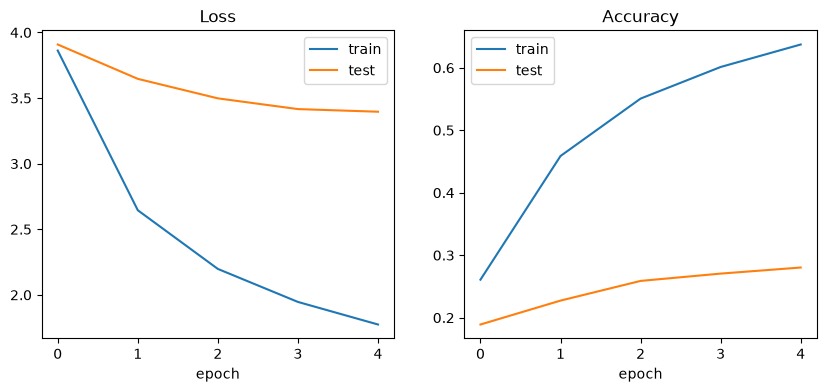

In [17]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(train_losses, label="train")
plt.plot(test_losses, label="test")
plt.title("Loss")
plt.xlabel("epoch")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(train_accs, label="train")
plt.plot(test_accs, label="test")
# plt.axhline(baseline_acc, color="gray", linestyle="--", label="baseline")
plt.title("Accuracy")
plt.xlabel("epoch")
plt.legend()

plt.savefig(out_dir/"curves.png", dpi=150, bbox_inches="tight")
plt.show()

In [18]:
end_time = time.perf_counter()
execution_time = end_time - start_time
print(execution_time)

646.0187242338434
